In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Impostazione dei percorsi coerente con la struttura del progetto
PROJECT_ROOT = Path.cwd().parent
DATASET_DIR = PROJECT_ROOT / "Dataset" / "lastfm-dataset-1K"
LISTENING_FILE = DATASET_DIR / "userid-timestamp-artid-artname-traid-traname.tsv"

print(f"Caricamento dataset da: {LISTENING_FILE}")

# 2. Caricamento del dataset (ottimizzato)
df = pd.read_csv(
    LISTENING_FILE,
    sep='\t',
    header=None,
    names=['user_id', 'timestamp', 'artist_mbid', 'artist_name', 'track_mbid', 'track_name'],
    on_bad_lines='skip'
)

print("Conversione dei timestamp in formato datetime (potrebbe richiedere qualche minuto)...")
df['timestamp'] = pd.to_datetime(df['timestamp'])

print(f"Completato! Dataset caricato con successo: {len(df):,} righe.")

Caricamento dataset da: C:\Users\dales\OneDrive\Desktop\PROGETTO SII\music-discovery-CMAB\Dataset\lastfm-dataset-1K\userid-timestamp-artid-artname-traid-traname.tsv
Conversione dei timestamp in formato datetime (potrebbe richiedere qualche minuto)...
Completato! Dataset caricato con successo: 19,098,853 righe.


Ordinamento del dataset per utente e traccia...
Calcolo dei delta temporali tra ascolti consecutivi...


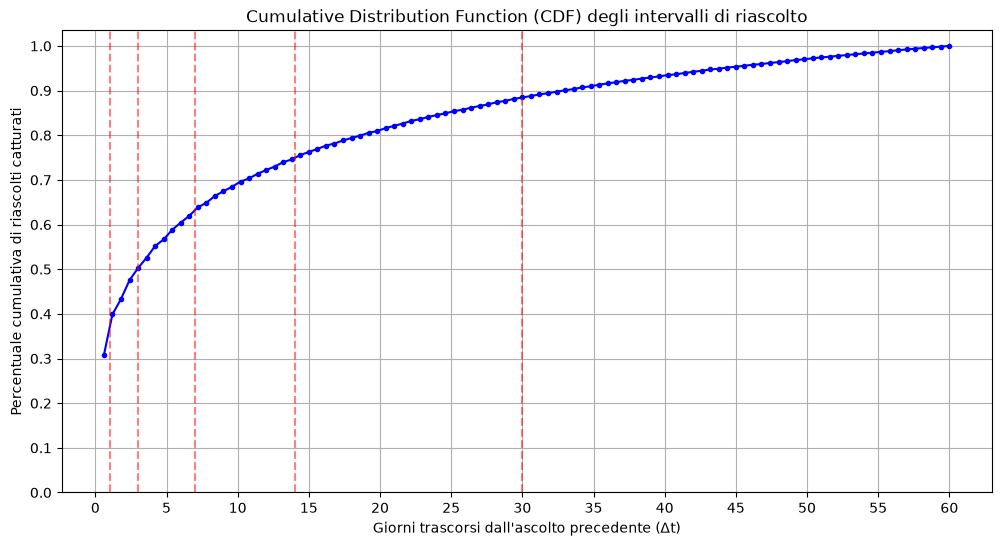


--- RISULTATI EMPIRICI PER LA SCELTA DEL REWARD ---
Percentuale di riascolti catturati per le finestre temporali chiave (rispetto al totale dei riascolti nel dataset):
Finestra di  1 giorni: 29.98% dei riascolti totali
Finestra di  3 giorni: 40.58% dei riascolti totali
Finestra di  7 giorni: 50.98% dei riascolti totali
Finestra di 14 giorni: 60.54% dei riascolti totali
Finestra di 30 giorni: 71.43% dei riascolti totali


In [2]:
# 1. Ordinamento cronologico rigoroso per utente e traccia
print("Ordinamento del dataset per utente e traccia...")
# Usiamo track_name per catturare i riascolti bypassando eventuali track_mbid mancanti
df_sorted = df.sort_values(by=['user_id', 'track_name', 'timestamp'])

# 2. Calcolo dei delta temporali vettorizzato
print("Calcolo dei delta temporali tra ascolti consecutivi...")
df_sorted['time_diff'] = df_sorted.groupby(['user_id', 'track_name'])['timestamp'].diff()

# 3. Conversione in giorni e rimozione dei primissimi ascolti (che non hanno un delta)
deltas_in_days = df_sorted['time_diff'].dt.total_seconds() / (24 * 3600)
deltas_in_days = deltas_in_days.dropna()

# 4. Creazione della CDF (filtrata a max 60 giorni per chiarezza visiva)
max_days = 60
deltas_filtered = deltas_in_days[deltas_in_days <= max_days]

count, bins_count = np.histogram(deltas_filtered, bins=100)
pdf = count / sum(count)
cdf = np.cumsum(pdf)

# 5. Plot del grafico
plt.figure(figsize=(12, 6))
plt.plot(bins_count[1:], cdf, marker='.', linestyle='-', color='b')

# Linee di riferimento strategiche per decidere \Delta
giorni_chiave = [1, 3, 7, 14, 30]
for g in giorni_chiave:
    plt.axvline(x=g, color='r', linestyle='--', alpha=0.5)

plt.title('Cumulative Distribution Function (CDF) degli intervalli di riascolto')
plt.xlabel('Giorni trascorsi dall\'ascolto precedente (Δt)')
plt.ylabel('Percentuale cumulativa di riascolti catturati')
plt.grid(True)
plt.xticks(np.arange(0, max_days + 1, 5))
plt.yticks(np.arange(0, 1.1, 0.1))
plt.show()

# 6. Estrazione dei dati quantitativi per giustificare la scelta all'esame
print("\n--- RISULTATI EMPIRICI PER LA SCELTA DEL REWARD ---")
print("Percentuale di riascolti catturati per le finestre temporali chiave (rispetto al totale dei riascolti nel dataset):")
total_reascolti = len(deltas_in_days)
for g in giorni_chiave:
    coverage = (deltas_in_days <= g).sum() / total_reascolti * 100
    print(f"Finestra di {g:2} giorni: {coverage:.2f}% dei riascolti totali")